## Q1 – Blob detection with scale-normalised LoG

Candidates after thresholding: 295
Final detections: 49


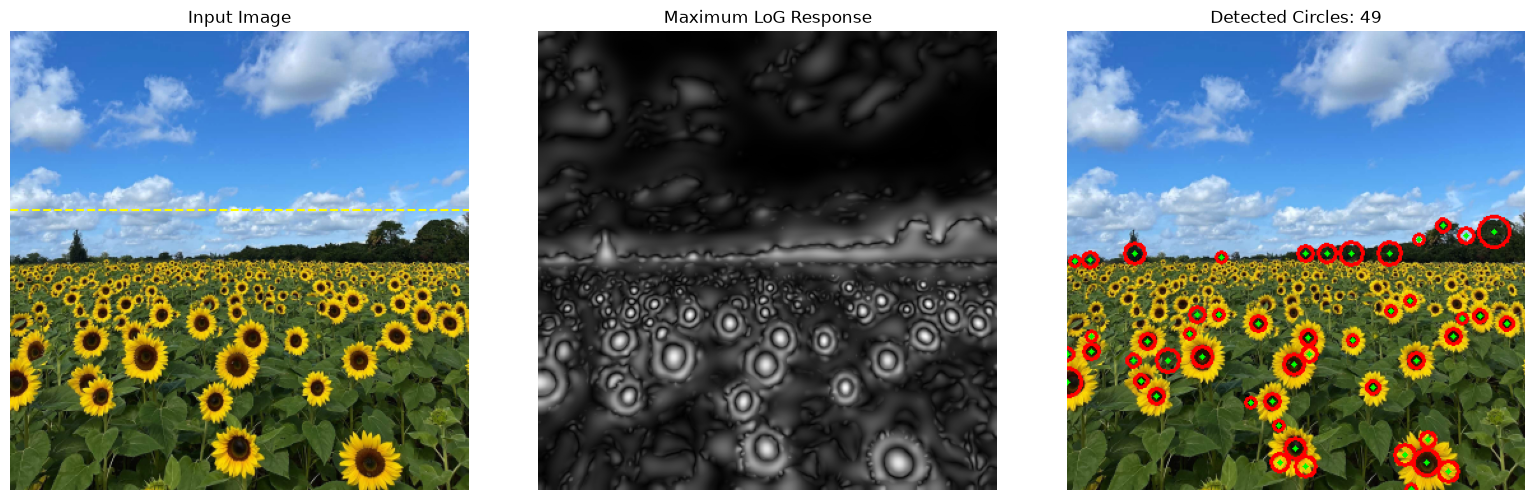


10 largest detected circles:
1. Center=(335, 157), Radius=12.02 px, Sigma=8.5, Response=211.35
2. Center=(0, 275), Radius=10.61 px, Sigma=7.5, Response=351.02
3. Center=(282, 338), Radius=9.90 px, Sigma=7.0, Response=355.18
4. Center=(223, 174), Radius=9.19 px, Sigma=6.5, Response=256.84
5. Center=(253, 174), Radius=9.19 px, Sigma=6.5, Response=244.78
6. Center=(79, 258), Radius=9.19 px, Sigma=6.5, Response=181.21
7. Center=(106, 255), Radius=8.49 px, Sigma=6.0, Response=369.22
8. Center=(179, 327), Radius=8.49 px, Sigma=6.0, Response=351.10
9. Center=(178, 261), Radius=7.78 px, Sigma=5.5, Response=357.78
10. Center=(53, 174), Radius=7.78 px, Sigma=5.5, Response=306.53


In [13]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Step 1: Load and resize the image
image_path = r"E:\SEM 5\vision\Assignment 02\EN3160_Assignment_02\a2images\the_berry_farms_sunflower_field.jpeg"

image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

im_reduced = cv.resize(
    image_rgb, (360, 360),
    interpolation=cv.INTER_AREA
)

gray = cv.cvtColor(
    im_reduced, cv.COLOR_RGB2GRAY
).astype(np.float32)

# Step 2: Set parameters
sigmas = np.arange(2.0, 9.0, 0.5)
threshold = 180.0
horizon_y = 140
minimum_sigma = 3.0

# Step 3: Generate scale-space LoG responses
responses = []

for sigma in sigmas:
    blurred = cv.GaussianBlur(
        gray, (0, 0),
        sigmaX=float(sigma),
        sigmaY=float(sigma)
    )

    laplacian = cv.Laplacian(
        blurred, cv.CV_32F, ksize=3
    )

    response = np.abs((sigma ** 2) * laplacian)
    responses.append(response)

responses = np.stack(responses, axis=0)

# Step 4: Find local maxima in space and scale
local_max = maximum_filter(
    responses,
    size=(3, 3, 3),
    mode="nearest"
)

is_local_max = (
    (responses == local_max) &
    (responses >= threshold)
)

scale_idx, y_coords, x_coords = np.where(is_local_max)

strengths = responses[
    scale_idx, y_coords, x_coords
]

print("Candidates after thresholding:", len(strengths))

# Step 5: Restrict detections to the sunflower field
field_mask = (
    (y_coords > horizon_y) &
    (sigmas[scale_idx] >= minimum_sigma)
)

scale_idx = scale_idx[field_mask]
y_coords = y_coords[field_mask]
x_coords = x_coords[field_mask]
strengths = strengths[field_mask]

# Step 6: Estimate circle radii
radii = np.sqrt(2.0) * sigmas[scale_idx]

# Step 7: Sort candidates by response strength
order = np.argsort(strengths)[::-1]
accepted = []

# Step 8: Suppress duplicate detections
minimum_distance = 12.0

for i in order:
    candidate = {
        "x": int(x_coords[i]),
        "y": int(y_coords[i]),
        "radius": float(radii[i]),
        "sigma": float(sigmas[scale_idx[i]]),
        "strength": float(strengths[i])
    }

    duplicate = False

    for previous in accepted:
        dx = candidate["x"] - previous["x"]
        dy = candidate["y"] - previous["y"]
        distance = np.hypot(dx, dy)

        suppression_distance = max(
            minimum_distance,
            1.8 * max(
                candidate["radius"],
                previous["radius"]
            )
        )

        if distance < suppression_distance:
            duplicate = True
            break

    if not duplicate:
        accepted.append(candidate)

print("Final detections:", len(accepted))

# Step 9: Draw circles
result = im_reduced.copy()

for detection in accepted:
    x = detection["x"]
    y = detection["y"]
    radius = max(3, int(round(detection["radius"])))

    cv.circle(
        result, (x, y), radius,
        (255, 0, 0), 2
    )

    cv.circle(
        result, (x, y), 2,
        (0, 255, 0), -1
    )

# Step 10: Display results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(im_reduced)
axes[0].axhline(
    horizon_y, color="yellow", linestyle="--"
)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(
    np.max(responses, axis=0), cmap="gray"
)
axes[1].set_title("Maximum LoG Response")
axes[1].axis("off")

axes[2].imshow(result)
axes[2].set_title(f"Detected Circles: {len(accepted)}")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Step 11: Report the largest detected circles
largest_circles = sorted(
    accepted,
    key=lambda item: item["radius"],
    reverse=True
)[:10]

print("\n10 largest detected circles:")

for i, detection in enumerate(largest_circles, 1):
    print(
        f"{i}. Center=({detection['x']}, {detection['y']}), "
        f"Radius={detection['radius']:.2f} px, "
        f"Sigma={detection['sigma']:.1f}, "
        f"Response={detection['strength']:.2f}"
    )


## Question 1: Sunflower Detection Using Laplacian of Gaussian

The sunflower field image was converted to grayscale and processed using the Laplacian of Gaussian (LoG) method at multiple scales. Local maxima in the scale-space were identified as potential sunflower heads. A response threshold and duplicate suppression were applied to reduce false detections and overlapping circles.

The sigma values ranged from **2.0 to 8.5 pixels**, with an increment of **0.5 pixels**. The radius of each detected blob was estimated using

$$
r \approx \sqrt{2}\sigma
$$

Not all sunflower heads were detected because some flowers overlap, have low contrast, or produce weak LoG responses. The detection results depend on the selected threshold, sigma range, and duplicate suppression settings.

The detected circles were drawn in red, with green dots marking their centres. The parameters of the largest detected circles, including their centre coordinates, radius, and corresponding sigma values, were obtained from the program. The `cv2.HoughCircles()` function was not used.

## Q2 – RANSAC line and circle fitting

In [5]:
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize
DIR = 'a2images'
np.random.seed(0)
N = 100; half_n = N//2; r = 10; x0_gt, y0_gt = 2, 3; s = r/16
t = np.random.uniform(0, 2*np.pi, half_n); n = s*np.random.randn(half_n)
x, y = x0_gt + (r+n)*np.cos(t), y0_gt + (r+n)*np.sin(t)
X_circ = np.column_stack((x, y))
s = 1.; m, b = -1, 2
x = np.linspace(-12, 12, half_n); y = m*x + b + s*np.random.randn(half_n)
X_line = np.column_stack((x, y)); X = np.vstack((X_circ, X_line))

### (a) Line with RANSAC

RANSAC fits a line using two random points. The perpendicular distance threshold is 1.5, and at least 30 inliers are required. The final line is refitted using SVD on the inliers.

In [6]:
def line_from_2pts(p, q):
    d = q - p; nrm = np.array([-d[1], d[0]]); nrm /= np.linalg.norm(nrm)
    return nrm[0], nrm[1], nrm @ p
def line_err(l, P): return np.abs(P @ np.array(l[:2]) - l[2])
def tls_line(P):
    mu = P.mean(0); _, _, Vt = np.linalg.svd(P - mu); nrm = Vt[1]
    return nrm[0], nrm[1], nrm @ mu

def ransac_line(X, thr=1.5, min_inl=30, iters=500):
    best = (None, None, 0, None)
    for _ in range(iters):
        i = np.random.choice(len(X), 2, replace=False)
        l = line_from_2pts(X[i[0]], X[i[1]]); inl = line_err(l, X) < thr
        if inl.sum() > best[2]: best = (l, inl, inl.sum(), i)
    assert best[2] >= min_inl, 'no consensus'
    return best

l0, inl_l, cnt, samp_l = ransac_line(X)
lbest = tls_line(X[inl_l])
print('best-sample line (a,b,d):', np.round(l0, 3), '| inliers:', cnt)
print('refit line (a,b,d):', np.round(lbest, 3), '| norm =', np.hypot(*lbest[:2]))
print('ground truth y=-x+2  ->  (a,b,d) = (0.707, 0.707, 1.414) up to sign')

best-sample line (a,b,d): [-0.7   -0.714 -1.637] | inliers: 56
refit line (a,b,d): [0.718 0.696 1.522] | norm = 1.0
ground truth y=-x+2  ->  (a,b,d) = (0.707, 0.707, 1.414) up to sign


### (b) Circle with RANSAC on the Remnant

Three points define a candidate circle. The radial error threshold is 1.5, with at least 20 inliers required. The best circle is refined using BFGS to minimise the sum of squared radial errors.

In [7]:
def circle_from_3pts(p1, p2, p3):
    A = np.array([2*(p2-p1), 2*(p3-p1)]); B = np.array([p2@p2 - p1@p1, p3@p3 - p1@p1])
    if abs(np.linalg.det(A)) < 1e-9: return None
    c = np.linalg.solve(A, B); return c[0], c[1], np.linalg.norm(p1 - c)
def circ_err(c, P): return np.abs(np.hypot(P[:,0]-c[0], P[:,1]-c[1]) - c[2])
def fit_circle(P, init):
    f = lambda c: np.sum((np.hypot(P[:,0]-c[0], P[:,1]-c[1]) - c[2])**2)
    return minimize(f, init, method='BFGS').x

def ransac_circle(R, thr=1.5, min_inl=20, iters=1000):
    best = (None, None, 0, None)
    for _ in range(iters):
        i = np.random.choice(len(R), 3, replace=False); c = circle_from_3pts(*R[i])
        if c is None or c[2] > 30: continue
        inl = circ_err(c, R) < thr
        if inl.sum() > best[2]: best = (c, inl, inl.sum(), i)
    assert best[2] >= min_inl, 'no consensus'
    return best

R = X[~inl_l]                                   # remove line consensus
c0, inl_c, cc, samp_c = ransac_circle(R)
cbest = fit_circle(R[inl_c], c0)
print('best-sample circle (x,y,r):', np.round(c0, 3), '| inliers:', cc)
print('refit circle (x,y,r):', np.round(cbest, 3), '| ground truth', (x0_gt, y0_gt, r))

best-sample circle (x,y,r): [ 1.98   3.391 10.133] | inliers: 44
refit circle (x,y,r): [1.868 3.067 9.949] | ground truth (2, 3, 10)


### (c) Combined plot

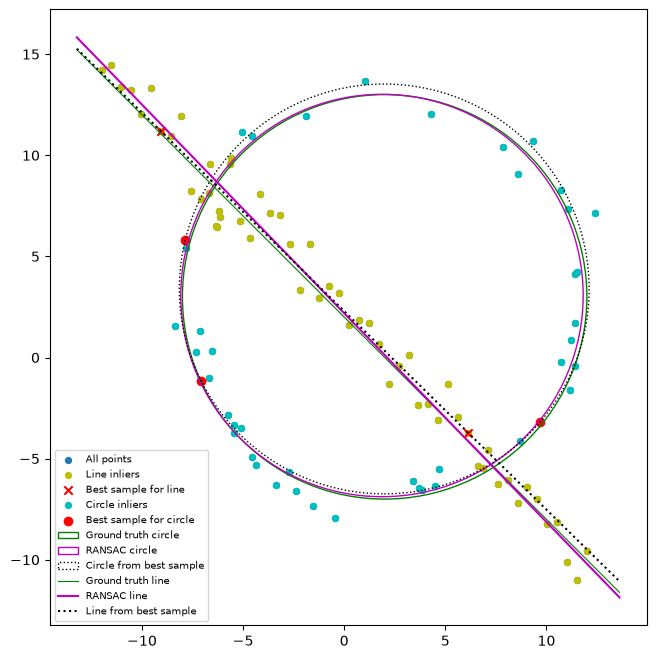

In [8]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(*X.T, s=18, label='All points')
ax.scatter(*X[inl_l].T, s=18, c='y', label='Line inliers')
ax.scatter(*X[samp_l].T, marker='x', c='r', label='Best sample for line')
ax.scatter(*R[inl_c].T, s=18, c='c', label='Circle inliers')
ax.scatter(*R[samp_c].T, c='r', label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(cbest[:2], cbest[2], color='m', fill=False, label='RANSAC circle'))
ax.add_patch(plt.Circle(c0[:2], c0[2], color='k', fill=False, ls=':', label='Circle from best sample'))
xs = np.array(ax.get_xlim())
ax.plot(xs, m*xs + b, 'g', lw=.8, label='Ground truth line')
ax.plot(xs, (lbest[2] - lbest[0]*xs)/lbest[1], 'm', label='RANSAC line')
a_, b_, d_ = l0; ax.plot(xs, (d_ - a_*xs)/b_, 'k:', label='Line from best sample')
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

### (d) What if the Circle Is Fitted First?

RANSAC finds the circle with 60 inliers, including 50 circle points and 10 line points. These extra points affect the circle estimate and remove genuine line points. Fitting the line first is safer because it leaves a cleaner circle in the remaining data. RANSAC can be biased when another structure is mistakenly treated as outliers.

In [9]:
np.random.seed(1)
c1, inl1, cn1, _ = ransac_circle(X)
print('circle-first inliers:', cn1, '| true circle pts:', inl1[:half_n].sum(), '| line pts:', inl1[half_n:].sum())
print('circle (x,y,r):', np.round(fit_circle(X[inl1], c1), 3))

circle-first inliers: 60 | true circle pts: 50 | line pts: 10
circle (x,y,r): [1.979 2.966 9.958]


## Q3 – Planar homography: superimposing the flag

wadham.jpg H =
 [[2.6170e-01 0.0000e+00 1.4720e+02]
 [7.4000e-02 2.3470e-01 2.0736e+02]
 [1.0000e-04 0.0000e+00 1.0000e+00]]
pcbs/AECC1.jpg H =
 [[ 5.445000e-01 -7.726000e-01  9.965870e+02]
 [ 2.043000e-01  2.016900e+00  2.116041e+02]
 [-0.000000e+00 -0.000000e+00  1.000000e+00]]
pcbs/ADAD1.jpg H =
 [[ 4.739000e-01 -6.341000e-01  8.605852e+02]
 [ 1.598000e-01  2.050100e+00  1.652324e+02]
 [-0.000000e+00  0.000000e+00  1.000000e+00]]


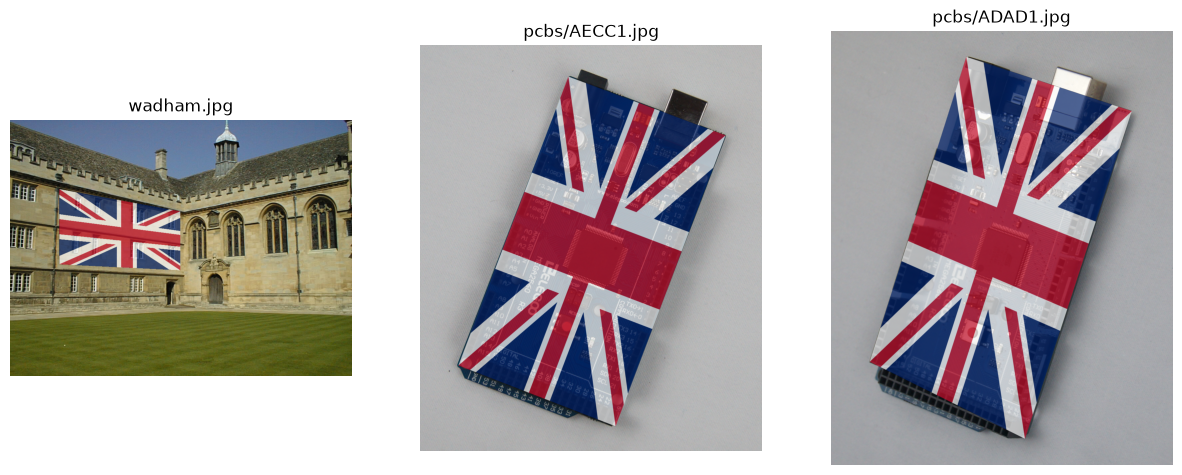

In [14]:
flag = cv.imread(f'{DIR}/flag.png'); fh, fw = flag.shape[:2]
src = np.float32([[0,0],[fw,0],[fw,fh],[0,fh]])

def superimpose(base, pts, alpha=0.7):
    H, _ = cv.findHomography(src, np.float32(pts))
    h, w = base.shape[:2]
    warped = cv.warpPerspective(flag, H, (w, h))
    mask = cv.warpPerspective(np.full((fh, fw), 255, np.uint8), H, (w, h)) > 0
    out = np.where(mask[..., None], (alpha*warped + (1-alpha)*base).astype(np.uint8), base)
    return out, H

# corners (TL, TR, BR, BL) were read off a downscaled preview; sc rescales to full resolution
sets = [('wadham.jpg',        1.28,      [(115,162),(398,214),(398,352),(115,338)]),
        ('pcbs/AECC1.jpg',    1/0.293,   [(292,62),(602,178),(385,752),(75,632)]),
        ('pcbs/ADAD1.jpg',    1/0.2905,  [(250,48),(555,148),(358,752),(72,610)])]
fig, ax = plt.subplots(1, 3, figsize=(15,6))
for a, (f, sc, p) in zip(ax, sets):
    im = cv.imread(f'{DIR}/{f}'); out, H = superimpose(im, [(px*sc, py*sc) for px, py in p])
    print(f, 'H =\n', np.round(H, 4))
    a.imshow(out[:, :, ::-1]); a.axis('off'); a.set_title(f)
plt.show()

**Notes:** The flag is stretched to fit the PCB, changing its aspect ratio. To avoid distortion, use a rectangle with the flag's original ratio. Accurate facade corners are also important, as small errors in the top and bottom lines can skew the flag.